# Micrograd from scratch

Building a small autograd engine and neural net library from first principles, following Andrej Karpathy's *micrograd* tutorial.

**Outline**
1. Derivatives numerically: what a slope means
2. The `Value` object and the computation graph
3. Manual backpropagation (chain rule)
4. A single optimization step
5. A neuron with `tanh`
6. Automating backprop: `_backward` and topological sort
7. The same neuron in PyTorch (sanity check)
8. `Neuron`, `Layer` and `MLP`
9. Training the MLP with gradient descent

## Setup

In [344]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import math
import random
import torch  # only used in section 7, as a reference implementation


## 1. Derivatives, numerically

We start with a simple scalar function $f(x) = 3x^2 - 4x + 5$.

In [345]:
def f(x):
    return 3*x**2 - 4*x + 5

In [346]:
f(3)

20

Apply it to an array of inputs (`x -> y`):

In [347]:
xs = np.arange(-5, 5, 0.25)
ys = f(xs)
ys

array([100.    ,  91.6875,  83.75  ,  76.1875,  69.    ,  62.1875,
        55.75  ,  49.6875,  44.    ,  38.6875,  33.75  ,  29.1875,
        25.    ,  21.1875,  17.75  ,  14.6875,  12.    ,   9.6875,
         7.75  ,   6.1875,   5.    ,   4.1875,   3.75  ,   3.6875,
         4.    ,   4.6875,   5.75  ,   7.1875,   9.    ,  11.1875,
        13.75  ,  16.6875,  20.    ,  23.6875,  27.75  ,  32.1875,
        37.    ,  42.1875,  47.75  ,  53.6875])

Plot the function:

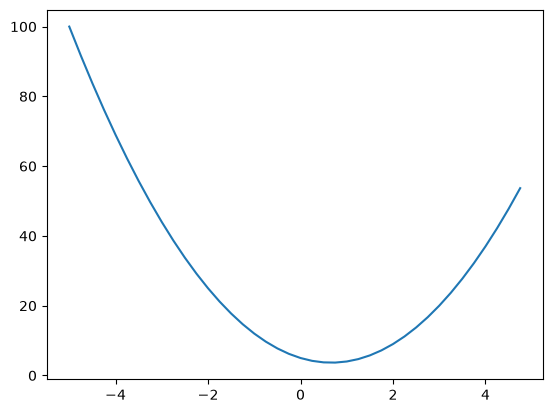

In [348]:
plt.plot(xs, ys)

### Slope of $f$ at a point

The derivative is the limit of $\frac{f(x+h) - f(x)}{h}$ as $h \to 0$. We approximate it with a tiny `h`. The sign of the slope depends on where we are on the curve.

In [349]:
# We can approximate the derivative by using a small value h and calculating its effect on the function f(x).
h = 0.0000001
x = 3.0
(f(x + h) - f(x)) / h

14.000000305713911

In [350]:
# Depending on the value of x, and our position on the curve, the slope might be positive or negative.
h = 0.0000001
x = -3.0
(f(x + h) - f(x)) / h

-21.999999688659955

### Derivatives with several inputs

With $d = a \cdot b + c$ we can nudge each input by `h` and measure how `d` responds. This gives the partial derivatives $\partial d/\partial a$, $\partial d/\partial b$ and $\partial d/\partial c$.

In [351]:
# We can give it more than just one input variable.

a = 2.0 
b = -3.0
c = 10.0
d = a*b +c
print(d)

4.0


**Nudge `a`**: the slope equals `b` (-3), so increasing `a` decreases `d`.

In [352]:
h = 0.0000001

a = 2.0 
b = -3.0
c = 10.0

d1 = a*b +c
a += h
d2 = a*b +c

print(('d1', d1))
print(('d2', d2))
print('slope', (d2 - d1) / h)

('d1', 4.0)
('d2', 3.9999997)
slope -2.9999999995311555


**Nudge `b`**: the slope equals `a` (2), so increasing `b` increases `d`.

In [353]:
# if we increase the term of the function the slope will be postitive. 
h = 0.0000001

a = 2.0 
b = -3.0
c = 10.0

d1 = a*b +c
b += h
d2 = a*b +c

print(('d1', d1))
print(('d2', d2))
print('slope', (d2 - d1) / h)

('d1', 4.0)
('d2', 4.0000002)
slope 1.9999999967268423


**Nudge `c`**: the slope is 1, because `c` is simply added and `h` passes through at the same ratio.

In [354]:
# In the case of adding to a constant, this will be slope of 1. As it will apply h in the same ratio as input.

h = 0.0000001

a = 2.0 
b = -3.0
c = 10.0

d1 = a*b +c
c += h
d2 = a*b +c

print(('d1', d1))
print(('d2', d2))
print('slope', (d2 - d1) / h)

('d1', 4.0)
('d2', 4.000000099999999)
slope 0.999999993922529


## 2. The `Value` object and the computation graph

`Value` wraps a scalar and remembers how it was produced (`_prev`, `_op`), so we can later walk the graph backwards. It also stores a `grad` (the derivative of the final output with respect to this node) and a `_backward` function that propagates the gradient to its children.

Two details worth remembering:
- `+=` in `_backward`: a node may be used several times, so gradients must **accumulate** rather than be overwritten.
- `tanh` is implemented as a single operation; its local derivative is $1 - \tanh^2(x)$.

In [355]:
# Value Object

class Value:
    def __init__(self, data, _children=(), _op='', label = ''):
        self.data =data
        self.grad = 0
        self._backward = lambda: None # Store the function that will be used to backpropagate the gradient through this node.
        self._prev = set(_children)
        self._op = _op
        self.label = label
    
    def __repr__(self):
        return f"Value(data={self.data})"
    
    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other) # Makes this more robust and turns a number into a value object if it is not already one.
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += 1.0 * out.grad
            other.grad += 1.0 * out.grad
        out._backward = _backward
        return out
    
    def __radd__(self, other):
        return self + other
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad # Just assining the gradient of the output node to the input nodes is not sufficient, we need to add them on top, as in cases where a node is used multiple times the gradients will accumulate.
            other.grad += self.data * out.grad 
        out._backward = _backward
        return out
    
    def __rmul__(self, other):
        return self * other
    
    def __truediv__(self, other):
        return self * other**-1
    
    def __pow__(self, other):
        assert isinstance(other, (int, float)), "only supporting int/float powers for now"
        out = Value(self.data**other, (self,), f'**{other}')
        def _backward():
            self.grad += (other * self.data**(other-1)) * out.grad
        out._backward = _backward
        return out
    
    def __neg__(self): # -self
        return self * -1
    
    def __sub__(self, other): # self - other
        return self + (-other)
    
    def tanh(self):
        n = self.data
        t = (math.exp(2*n) - 1) / (math.exp(2*n) + 1)
        out = Value(t, (self,), 'tanh')
        
        def _backward():
            self.grad += (1 - t**2) * out.grad
        out._backward = _backward
        return out
    
    def exp(self):
        n = self.data
        out = Value(math.exp(n), (self,), 'exp')
        
        def _backward():
            self.grad += out.data * out.grad
        out._backward = _backward
        return out
    
    def backward(self):
        # Topological order all of the children in the graph
        topo = []
        visited = set()
        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)
        build_topo(self)

        self.grad = 1.0
        for node in reversed(topo):
            node._backward()


In [356]:
a = Value(2.0, label='a')
b = Value(-3.0, label='b')
b-a


Value(data=-5.0)

### Building a small expression

$L = (a \cdot b + c) \cdot f$, with the gradients (for now) filled in **by hand** below.

In [357]:
a = Value(2.0, label ='a')
b = Value(-3.0, label ='b')
c = Value(10.0, label ='c')

e = a*b 
e.label = 'e'

d = e + c
d.label = 'd'

f_ = Value(-2.0, label ='f')  # f_ so we don't overwrite the function f() from section 1
L = d * f_

L.label = 'L'
L.grad = 1
f_.grad = d.data
d.grad = f_.data
e.grad = d.grad * 1
c.grad = d.grad * 1
a.grad = e.grad * b.data
b.grad = e.grad * a.data
d

Value(data=4.0)

In [358]:
d._prev, d._op

({Value(data=-6.0), Value(data=10.0)}, '+')

### Visualizing the graph

Helper functions that trace all nodes and edges from a root and draw them with graphviz.

In [359]:
from graphviz import Digraph

def trace(root):
    # build a set of all nodes and edges in the graph
    nodes, edges = set(), set()
    
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})  # LR = left to right
    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # create a node for each value
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of an operation, create a node for the op
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)
    for n1, n2 in edges:
        # connect the children to their parents
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)
    return dot

#### Forward pass

Some leaf nodes are weights and others are input data. `L` is the final output (think: loss). Next we run backpropagation to find how much each node influences `L`.

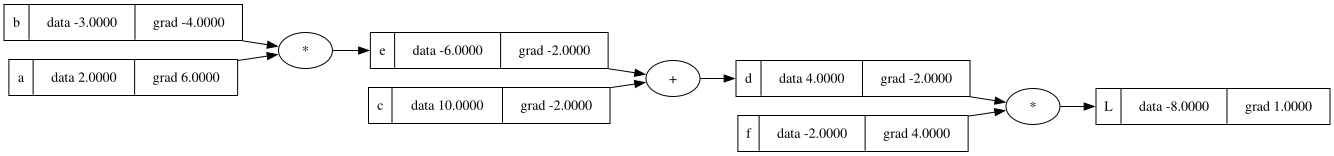

In [360]:
draw_dot(L)
# Some of the leaf nodes are weights, and others are input values. The leaf nodes are the ones that we care about when calculating the gradient. 
# L below represents the Loss function, which is the final output L. As a next step, we will run backpropagation to calculate the gradients of the leaf nodes. 
# The gradients will tell us how much each leaf node contributed to the final output L.

## 3. Manual backpropagation

### Checking a gradient numerically
`check_grad_b()` recomputes `L` with `b` nudged by `h` and compares it to the analytic gradient (`b.grad`). It is a gradient check done by hand.

In [361]:
def check_grad_b():
    """Numerically estimate dL/db by nudging b by h; compare with b.grad."""
    h = 0.00001
    
    a = Value(2.0, label ='a')
    b = Value(-3.0, label ='b')
    c = Value(10.0, label ='c')

    e = a*b 
    e.label = 'e'

    d = e + c
    d.label = 'd'

    f_ = Value(-2.0, label ='f')
    L = d * f_

    L.label = 'L'
    L1 = L.data
    
    a = Value(2.0, label ='a')
    b = Value(-3.0 +h, label ='b')
    c = Value(10.0, label ='c')

    e = a*b 
    e.label = 'e'

    d = e + c
    d.label = 'd'

    f_ = Value(-2.0, label ='f')
    L = d * f_

    L.label = 'L'
    L2 = L.data
    
    print((L2 - L1)/h)
    
check_grad_b()

-4.000000000026205


### Why `dL/dd = f` and `dL/df = d`

For $L = d \cdot f$ we want $\frac{dL}{dd}$:

$$\frac{(d+h) f - d f}{h} = \frac{d f + h f - d f}{h} = \frac{h f}{h} = f$$

By symmetry, $\frac{dL}{df} = d$.

### Chain rule

To get gradients of earlier nodes, multiply the **local derivative** by the gradient flowing in from the output (see the chain rule on Wikipedia for an intuitive example).

- For `+` the local derivative is 1, so the gradient is simply **routed** to both summands (`c` and `e` get `d.grad`).
- For `*` the local derivative of one factor is the *other* factor.

For example, with $e = a \cdot b$ and $\frac{dL}{de} = -2.0$:

$$\frac{de}{da} = b \quad\Rightarrow\quad \frac{dL}{da} = \frac{dL}{de} \cdot \frac{de}{da} = -2.0 \cdot -3.0 = 6.0$$

## 4. A simple optimization step

Nudge the leaf nodes a small step **in the direction of the gradient** and `L` should increase. To *minimize* a loss we would step against the gradient.

In [362]:
# We can now do a tiny optimization example: 
a.data += 0.01 * a.grad # -> we move a tiny step into the direction of the gradient. 
b.data += 0.01 * b.grad
c.data += 0.01 * c.grad
f_.data += 0.01 * f_.grad

e = a * b
d = e + c
L = d * f_

print(L.data)

-7.286496


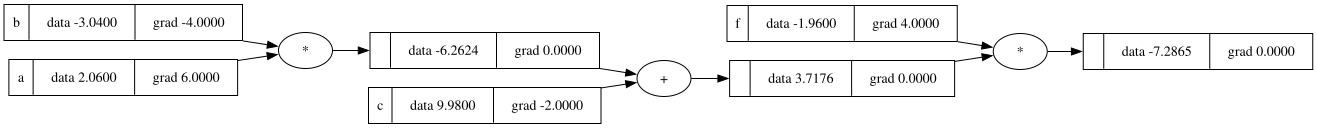

In [363]:
draw_dot(L)

## 5. A neuron

A neuron computes a weighted sum of its inputs plus a bias and squashes it with an activation function. `tanh` maps any input to the range (-1, 1):

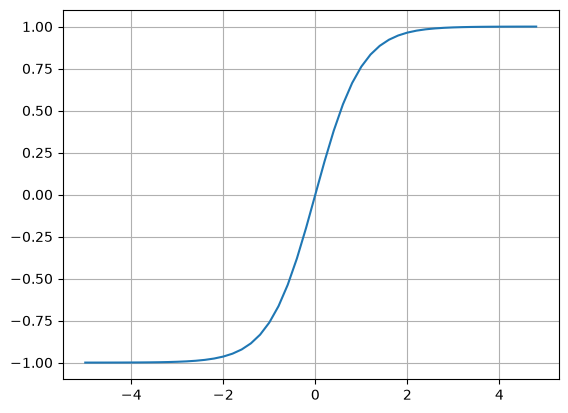

In [364]:
plt.plot(np.arange(-5, 5, 0.2), np.tanh(np.arange(-5, 5, 0.2))) # <- This is an activation function, that squashes the output of a neuron into a range between -1 and 1. 
plt.grid()

### Forward pass of a single neuron

Inputs `x1, x2`, weights `w1, w2` and a bias `b`: $o = \tanh(x_1 w_1 + x_2 w_2 + b)$. The bias shifts the activation function left or right. (The bias value is chosen so the numbers come out nicely.)

In [365]:
# Example with inputs x1, x2 and weights w1, w2, and bias b. The output of the neuron is calculated as the weighted sum of the inputs plus the bias, passed through an activation function (tanh in this case).
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.881373587019543, label='b') # <- This is the bias term, which allows the neuron to shift the activation function left or right.

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label = 'x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b;
n.label = 'n'
o = n.tanh(); o.label = 'o'
# n is the raw activation (before squashing); o applies the activation function tanh.


### Manual backward pass through the neuron

Working backwards from `o`:
- $do/do = 1$
- $do/dn = 1 - \tanh^2(n) = 1 - o^2$
- sums route the gradient unchanged
- products: each factor gets the other factor times the incoming gradient

In [366]:
o.grad = 1.0 # <- dO/dO is 1.0, as the gradient of a variable with respect to itself is always 1.0.
# for the derivative of tanh we can just square o, since the derivative of tanh is 1 - tanh^2(x). So we can calculate the gradient of n with respect to o as follows:
n.grad = (1 - o.data**2)
# As we learned earlier, nodes that are summed will have the same gradient, carried over from the output node.
# We can therefore apply:
x1w1_plus_x2w2.grad = n.grad
b.grad = n.grad
# Again, before that we have another sum, so we can apply the same logic:
x1w1.grad = x1w1_plus_x2w2.grad * 1
x2w2.grad = x1w1_plus_x2w2.grad * 1
# Now we can calculate the gradients of the weights and inputs by applying the chain rule:
x1.grad = x1w1.grad * w1.data
w1.grad = x1w1.grad * x1.data
x2.grad = x2w2.grad * w2.data
w2.grad = x2w2.grad * x2.data

## 6. Automating backpropagation

### `_backward` per operation
Each operation in the `Value` class from section 2 stores its own local backward step in `_backward`. We rebuild the neuron with it:

In [367]:
# Rebuild the neuron from section 5 (fresh nodes, so every grad starts at 0).
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.881373587019543, label='b') # <- This is the bias term, which allows the neuron to shift the activation function left or right.

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label = 'x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b;
n.label = 'n'
o = n.tanh(); o.label = 'o'


Call `_backward` manually, in the right order (output first, from the end of the graph to the leaves):

In [368]:
# After implementing the backward method, we can now calculate the gradients of the leaf nodes by calling the backward method on the output node o. 
# This will propagate the gradients back through the computation graph, updating the grad attribute of each node accordingly.
o.grad = 1.0
o._backward()
n._backward()
b._backward()
x1w1_plus_x2w2._backward()
x1w1._backward()
x2w2._backward()

### Topological sort

To do this automatically, order the nodes so that every node comes **after** all of its children. Processing it in reverse guarantees a node's gradient is complete before it is propagated further.

Gradients accumulate (`+=`), so we rebuild the neuron first to start from `grad = 0`:

In [369]:
# Rebuild the neuron from section 5 (fresh nodes, so every grad starts at 0).
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.881373587019543, label='b') # <- This is the bias term, which allows the neuron to shift the activation function left or right.

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label = 'x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b;
n.label = 'n'
o = n.tanh(); o.label = 'o'


In [370]:
# In order to automate this, we need to use a topological sort to ensure that we visit the nodes in the correct order. This will allow us to calculate the gradients of the leaf nodes in a single pass through the computation graph.
topo = []
visited = set()
def build_topo(v):
    if v not in visited:
        visited.add(v)
        for child in v._prev:
            build_topo(child)
        topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543),
 Value(data=1.0),
 Value(data=0.0),
 Value(data=0.0),
 Value(data=-3.0),
 Value(data=2.0),
 Value(data=-6.0),
 Value(data=-6.0),
 Value(data=0.8813735870195432),
 Value(data=0.7071067811865476)]

Run the backward pass over the reversed topological order:

In [371]:
# topo was built in the previous cell
o.grad = 1.0
for node in reversed(topo):
    node._backward()


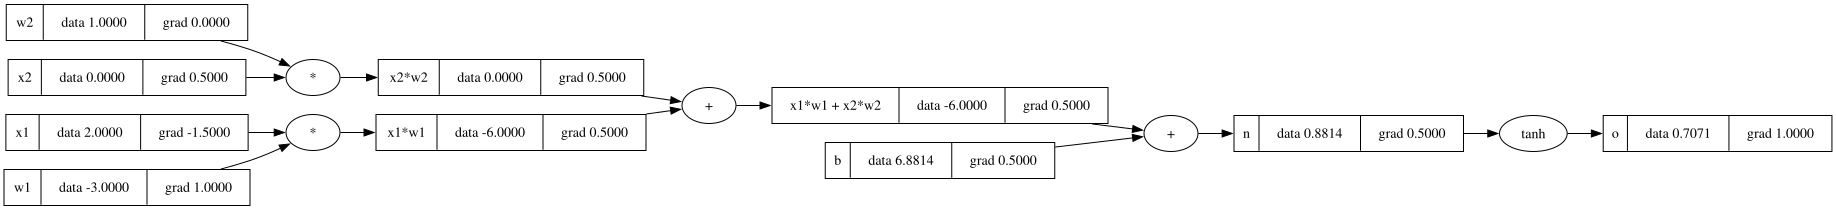

In [372]:
draw_dot(o)

### `Value.backward()`

The topological sort is wrapped into `backward()`, so a single `o.backward()` call fills in all gradients.

Gradients accumulate (`+=`), so we instantiate the neuron again to start from `grad = 0`:

In [373]:
# Rebuild the neuron from section 5 (fresh nodes, so every grad starts at 0).
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.881373587019543, label='b') # <- This is the bias term, which allows the neuron to shift the activation function left or right.

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label = 'x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b;
n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()


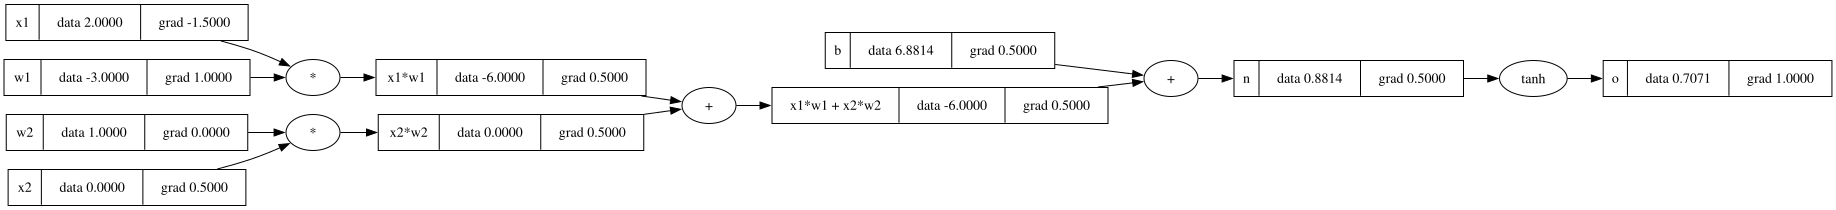

In [374]:
draw_dot(o)

### Flexibility of the atomic operations

To practise: `tanh` can be rebuilt from simpler operations (`exp`, `-`, `+`, `/`). The result is the same, only the graph is bigger.

In [375]:
# Rebuild the neuron from section 5 (fresh nodes, so every grad starts at 0).
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')

b = Value(6.881373587019543, label='b') # <- This is the bias term, which allows the neuron to shift the activation function left or right.

x1w1 = x1 * w1; x1w1.label = 'x1*w1'
x2w2 = x2 * w2; x2w2.label = 'x2*w2'
x1w1_plus_x2w2 = x1w1 + x2w2; x1w1_plus_x2w2.label = 'x1*w1 + x2*w2'
n = x1w1_plus_x2w2 + b;
n.label = 'n'

e = (2*n).exp(); e.label = 'e'
o = (e-1)/(e+1); o.label = 'o'

# Equivalent to o = n.tanh(), built from exp, -, + and /
o.backward()


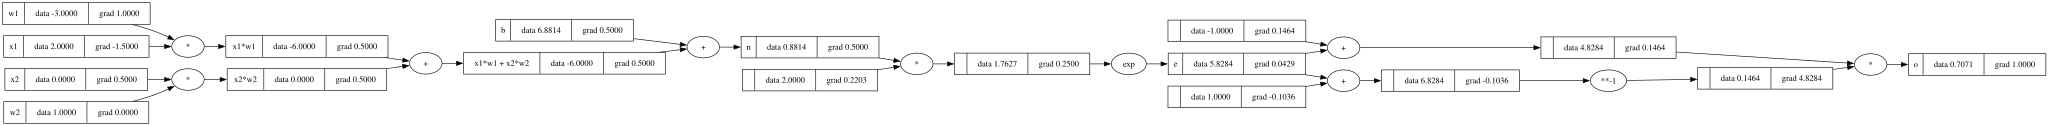

In [376]:
draw_dot(o)

## 7. The same neuron in PyTorch

A sanity check: PyTorch gives the same gradients. It works on **tensors** (multi-dimensional arrays: scalars, vectors, matrices, ...), whereas our `Value` only handles single numbers. Here we use 0-dim tensors, so it is directly comparable.

In [377]:
# Recreate the same example as above, but using PyTorch tensors instead of the custom Value class.
x1 = torch.tensor(2.0, requires_grad=True)
x2 = torch.tensor(0.0, requires_grad=True)
w1 = torch.tensor(-3.0, requires_grad=True)
w2 = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(6.881373587019543, requires_grad=True)
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('-----')
print(f'x1.grad: {x1.grad.item()}')
print(f'x2.grad: {x2.grad.item()}')
print(f'w1.grad: {w1.grad.item()}')
print(f'w2.grad: {w2.grad.item()}')

0.7071067094802856
-----
x1.grad: -1.5000003576278687
x2.grad: 0.5000001192092896
w1.grad: 1.000000238418579
w2.grad: 0.0


## 8. `Neuron`, `Layer` and `MLP`

- `Neuron(nin)`: `nin` random weights and a bias; computes `tanh(w·x + b)`.
- `Layer(nin, nout)`: `nout` neurons that all see the same input.
- `MLP(nin, nouts)`: layers chained together, e.g. `MLP(3, [4, 4, 1])` = 3 inputs, two hidden layers of 4 neurons, 1 output.

Each class has `parameters()` so we can later update every weight and bias in a loop.

In [378]:
class Neuron:
    def __init__(self, nin):
       self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
       self.b = Value(random.uniform(-1, 1)) 
       
    def __call__(self, x):
        # w*x +b
        act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out
    
    def parameters(self):
        return self.w + [self.b]
    
class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]
    
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]
    
    def __call__(self, x):
        outs = [n(x) for n in self.neurons]
        return outs[0] if len(outs) == 1 else outs
    
class MLP:
    def __init__(self, nin, nouts):
        sz = [nin] + nouts
        self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]
    
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]
    
    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

In [379]:
x = [2.0, 3.0, -1]
mlp = MLP(3, [4, 4, 1])  # named mlp (not n) so it doesn't clash with the node n from the neuron examples
mlp(x)

Value(data=-0.9211046327697218)

In [380]:
len(mlp.parameters())

41

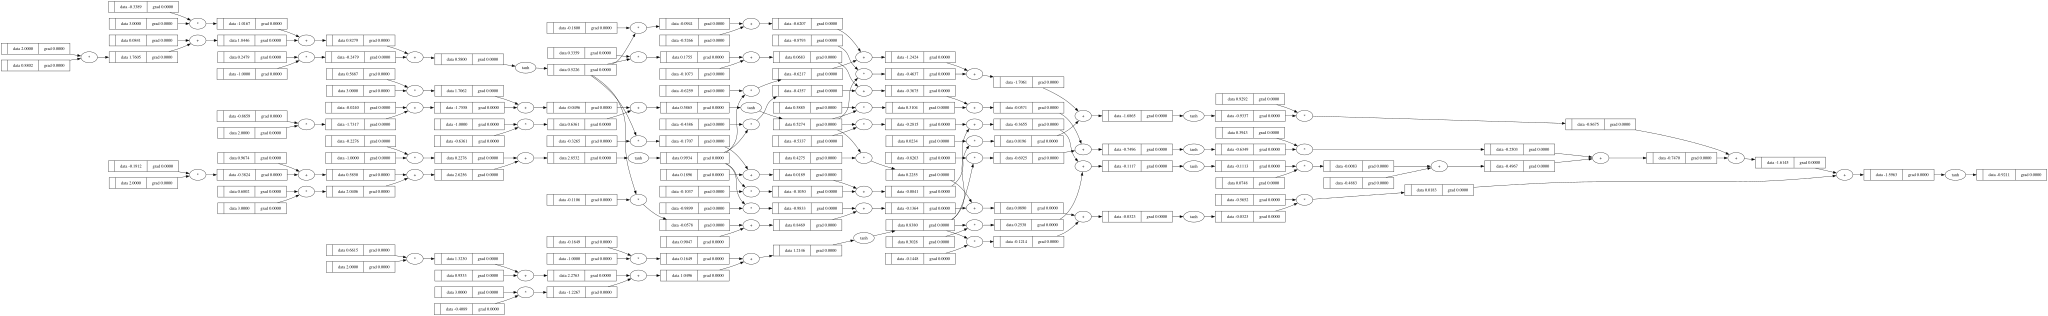

In [381]:
draw_dot(mlp(x))

## 9. Training the MLP

A tiny dataset: 4 examples with 3 inputs each and a desired target of +1 or -1. The loss is the **sum of squared errors**; it is 0 only when every prediction is exactly its target.

In [382]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]  # desired targets

ypred = [mlp(x) for x in xs]
ypred

[Value(data=-0.9211046327697218),
 Value(data=-0.5842385545015093),
 Value(data=-0.8287244669435943),
 Value(data=-0.9167582310330784)]

In [383]:
[(yout - ygt)**2 for yout, ygt in zip(ypred, ys)]

[Value(data=3.6906430100492873),
 Value(data=0.17285757956299444),
 Value(data=0.02933530822375594),
 Value(data=3.673962116233056)]

In [384]:
# Sum of squared errors between predictions and targets.
loss = sum((yout - ygt)**2 for yout, ygt in zip(ypred, ys))
loss

Value(data=7.566798014069094)

In [385]:
loss.backward()

In [386]:
# Every parameter now has a gradient: how much the loss changes if we nudge it.
w = mlp.layers[0].neurons[0].w[0]
print(w.data, w.grad)

0.8802464431673871 -0.11690414810859466


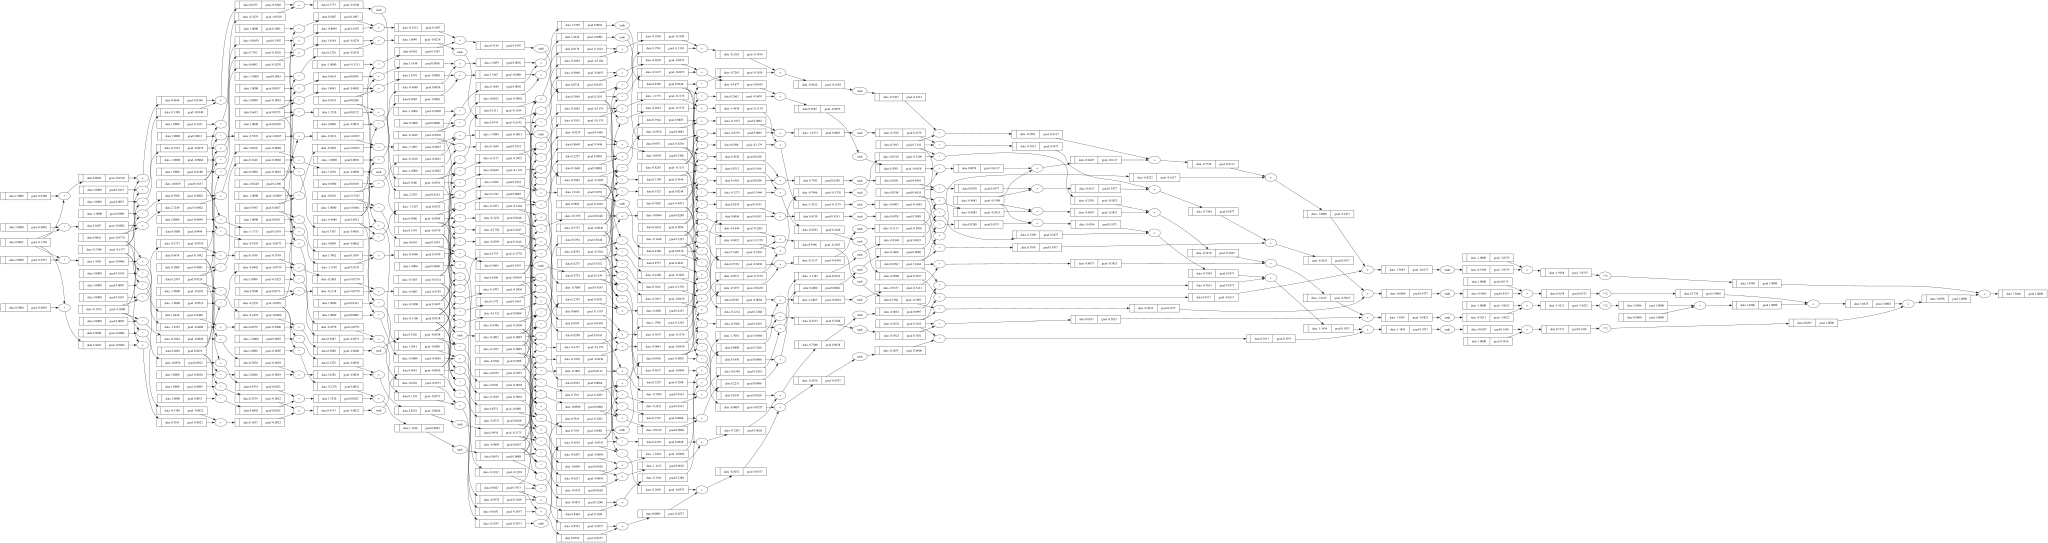

In [387]:
draw_dot(loss)

### One gradient descent step

The gradient points in the direction that *increases* the loss, so we step **against** it, scaled by a small learning rate (0.05).

In [388]:
for p in mlp.parameters():
    p.data += -0.05 * p.grad

print(w.data, w.grad)  # data moved; grad is still the old one

0.8860916505728168 -0.11690414810859466


### Forward pass again

The loss must be **recomputed** with a new forward pass: `ypred` and `loss` still hold the values from before the update, so reusing them would show no change.

In [389]:
ypred = [mlp(x) for x in xs]
loss = sum((yout - ygt)**2 for yout, ygt in zip(ypred, ys))
loss.data  # should be lower than before the step

7.307751397514002

### The full training loop

Each iteration: forward pass, **reset the gradients to 0**, backward pass, update. The reset matters because `_backward` uses `+=`; without it, gradients from earlier iterations pile up and the updates go in the wrong direction.

In [390]:
for k in range(20):
    # forward pass
    ypred = [mlp(x) for x in xs]
    loss = sum((yout - ygt)**2 for yout, ygt in zip(ypred, ys))

    # backward pass (zero the grads first, they accumulate)
    for p in mlp.parameters():
        p.grad = 0.0
    loss.backward()

    # update
    for p in mlp.parameters():
        p.data += -0.05 * p.grad

    print(k, loss.data)

0 7.307751397514002
1 6.860432449635456
2 5.8926947718338045
3 3.9830387976129575
4 2.895515284714207
5 2.623738495346027
6 2.4730383184510885
7 2.325494844600588
8 2.141548471367181
9 1.881736596351975
10 1.505132491979835
11 1.039076520498084
12 0.6516178674596135
13 0.4341507354191285
14 0.3194808750425994
15 0.2523419305162179
16 0.20876499004230437
17 0.17824149565991812
18 0.15564779361403985
19 0.13822475138704032


In [391]:
# Predictions should now be close to the targets [1.0, -1.0, -1.0, 1.0]
ypred

[Value(data=0.8301295354448994),
 Value(data=-0.8319585657450909),
 Value(data=-0.7979353317281452),
 Value(data=0.7992496005767038)]